# 03 — Parameter estimation and precision

Goal: estimate $\mu$, $\sigma$ for each ETF and $\rho$ between them, in annual units, and show how precise and
stable each estimate is.

Time unit: years, with $\Delta t = 1/252$ for daily data; $n$ is the number of returns and $T = n\Delta t$
the sample length in years. Maximum likelihood estimators (sample moments of the log returns):

$$\hat\nu = \frac{\bar X}{\Delta t}, \qquad \hat\sigma^2 = \frac{1}{(n-1)\Delta t}\sum_{k=1}^{n}(X_k - \bar X)^2, \qquad \hat\mu = \hat\nu + \tfrac{1}{2}\hat\sigma^2$$

where $\nu = \mu - \sigma^2/2$ is the drift of log price. **Which one is used later:** $\nu$ governs the median
and the typical (log) growth of wealth, $\ln W_T \sim \mathcal{N}(\ln W_0 + \nu_p T, \sigma_p^2 T)$;
$\mu$ is the drift of the price itself and enters the portfolio formulas of notebook 04
($\mu_p = r + \pi(w\mu_A + (1-w)\mu_G - r)$), from which $\nu_p = \mu_p - \tfrac12\sigma_p^2$ follows.

Standard errors under GBM:

$$\operatorname{SE}(\hat\nu) \approx \frac{\hat\sigma}{\sqrt{T}}, \qquad \operatorname{SE}(\hat\sigma) \approx \frac{\hat\sigma}{\sqrt{2n}}$$

Outputs: `tables/estimates.csv` / `.tex` (Table 3), `tables/estimates_by_frequency.*`,
`tables/estimates_by_year.csv`, `tables/estimates_rolling.csv`, Figs 7, 7b and 8.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

import config as cfg
from src import gbm_utils as gu

gu.set_style()
pd.set_option("display.width", 140)
KEYS = list(cfg.TICKERS)
DT = cfg.DT

daily = pd.read_csv(gu.CLEAN_DIR / "log_returns.csv", index_col="date", parse_dates=True)[KEYS]
X = daily.to_numpy()
n = len(X)
T_years = n * DT
print(f"n = {n} daily returns, T = n * dt = {T_years:.2f} years")

n = 3029 daily returns, T = n * dt = 12.02 years


## 0. Check the estimators on simulated GBM

Before using them on data, the estimators and their i.i.d. 95% intervals are applied to 1,000 simulated
bivariate GBM samples with known parameters and the same $n$ and $\Delta t$ as the data. The test inputs below
are chosen to be of similar size to equity parameters; they are not estimates. Coverage should be close to 95%.

In [2]:
TRUE = {"mu": np.array([0.09, 0.13]), "sigma": np.array([0.15, 0.13]), "rho": 0.6}   # test inputs only
nu_true = TRUE["mu"] - TRUE["sigma"] ** 2 / 2
cov_true = np.array([[1, TRUE["rho"]], [TRUE["rho"], 1]]) * np.outer(TRUE["sigma"], TRUE["sigma"]) * DT
rng = np.random.default_rng(cfg.SEED)
hits = []
for _ in range(cfg.N_SIM_CHECK):
    Xs = rng.multivariate_normal(nu_true * DT, cov_true, size=n)
    row = {}
    for i in range(2):
        e = gu.gbm_estimates(Xs[:, i], DT)
        row[f"nu_{i}"] = e["nu_lo"] <= nu_true[i] <= e["nu_hi"]
        row[f"mu_{i}"] = e["mu_lo"] <= TRUE["mu"][i] <= e["mu_hi"]
        row[f"sigma_{i}"] = e["sigma_lo"] <= TRUE["sigma"][i] <= e["sigma_hi"]
    lo, hi = gu.fisher_ci(np.corrcoef(Xs.T)[0, 1], n)
    row["rho"] = lo <= TRUE["rho"] <= hi
    hits.append(row)
coverage = pd.DataFrame(hits).mean()
mc_se = np.sqrt(0.95 * 0.05 / cfg.N_SIM_CHECK)
print(f"Coverage of i.i.d. 95% intervals on simulated GBM (Monte Carlo SE {mc_se:.3f}):")
print(coverage.round(3).to_string())

Coverage of i.i.d. 95% intervals on simulated GBM (Monte Carlo SE 0.007):
nu_0       0.936
mu_0       0.935
sigma_0    0.944
nu_1       0.939
mu_1       0.938
sigma_1    0.944
rho        0.946


## 1. Point estimates and i.i.d. 95% confidence intervals

$t$-interval for $\nu$, $\chi^2$ interval for $\sigma$, delta-method interval for $\mu$
($\operatorname{Var}(\hat\mu) \approx \operatorname{SE}(\hat\nu)^2 + \hat\sigma^4/(2(n-1))$), and Fisher
$z$-transform interval for $\rho$.

In [3]:
est = {k: gu.gbm_estimates(daily[k], DT) for k in KEYS}
rho_hat = daily["AU"].corr(daily["GL"])
rho_lo, rho_hi = gu.fisher_ci(rho_hat, n)

rows = []
for k in KEYS:
    e = est[k]
    for p in ["nu", "mu", "sigma"]:
        rows.append({"parameter": f"{p}_{k}", "estimate": e[p], "iid lo": e[f"{p}_lo"], "iid hi": e[f"{p}_hi"]})
rows.append({"parameter": "rho", "estimate": rho_hat, "iid lo": rho_lo, "iid hi": rho_hi})
iid = pd.DataFrame(rows).set_index("parameter")
iid.style.format("{:.4f}")

,estimate,iid lo,iid hi
parameter,,,
nu_AU,0.0812,-0.0017,0.1640
mu_AU,0.0919,0.0091,0.1748
sigma_AU,0.1465,0.1429,0.1503
nu_GL,0.1225,0.0482,0.1967
mu_GL,0.1311,0.0569,0.2053
sigma_GL,0.1313,0.1281,0.1347
rho,0.5855,0.5616,0.6084


### The precision contrast

$\operatorname{SE}(\hat\nu) = \hat\sigma/\sqrt{T}$ depends only on the length of the sample in years, while
$\operatorname{SE}(\hat\sigma) = \hat\sigma/\sqrt{2n}$ depends on the number of observations. The cell below
prints both for the daily data, and the sample length that would be needed for $\operatorname{SE}(\hat\nu)$ to
reach 1% per year.

In [4]:
for k in KEYS:
    e = est[k]
    print(f"{k}: sigma = {e['sigma']:.2%}, T = {e['T']:.2f} y, n = {e['n']}")
    print(f"    SE(nu)    = sigma/sqrt(T)  = {e['se_nu']:.2%} per year   (relative to nu:    {e['se_nu'] / abs(e['nu']):.0%})")
    print(f"    SE(sigma) = sigma/sqrt(2n) = {e['se_sigma']:.2%} per year   (relative to sigma: {e['se_sigma'] / e['sigma']:.1%})")
    print(f"    years of data for SE(nu) = 1% per year: (sigma / 0.01)^2 = {(e['sigma'] / 0.01) ** 2:.0f}")

AU: sigma = 14.65%, T = 12.02 y, n = 3029
    SE(nu)    = sigma/sqrt(T)  = 4.23% per year   (relative to nu:    52%)
    SE(sigma) = sigma/sqrt(2n) = 0.19% per year   (relative to sigma: 1.3%)
    years of data for SE(nu) = 1% per year: (sigma / 0.01)^2 = 215
GL: sigma = 13.13%, T = 12.02 y, n = 3029
    SE(nu)    = sigma/sqrt(T)  = 3.79% per year   (relative to nu:    31%)
    SE(sigma) = sigma/sqrt(2n) = 0.17% per year   (relative to sigma: 1.3%)
    years of data for SE(nu) = 1% per year: (sigma / 0.01)^2 = 172


## 2. Robust intervals: Newey–West (HAC) and block bootstrap

Notebook 02 found autocorrelation and volatility clustering, which the i.i.d. formulas ignore.

- **HAC:** Newey–West standard error of the mean daily return (Bartlett kernel, lag from the rule
  $\lfloor 4(n/100)^{2/9}\rfloor$), giving a robust interval for $\nu$.
- **Block bootstrap:** moving-block bootstrap with 20-day blocks and 5,000 resamples. Blocks are drawn
  jointly for both ETFs, which keeps their correlation and the short-run dependence within each block.
  95% intervals are bootstrap percentiles.

In [5]:
lags = cfg.NW_LAGS or gu.newey_west_lags(n)
print(f"Newey-West lags: {lags}")
hac = {}
for k in KEYS:
    se_hac = gu.hac_se_mean(daily[k], lags) / DT
    hac[k] = se_hac
    print(f"{k}: SE(nu) i.i.d. {est[k]['se_nu']:.3%}   HAC {se_hac:.3%}   ratio {se_hac / est[k]['se_nu']:.2f}")

rng = np.random.default_rng(cfg.SEED)
boot = gu.bootstrap_gbm_stats(X, DT, cfg.BLOCK_LENGTH, cfg.N_BOOT, rng)
boot = boot.rename(columns=lambda c: c.replace("_0", "_AU").replace("_1", "_GL"))
print(f"Bootstrap: {len(boot)} resamples, block length {cfg.BLOCK_LENGTH} days")

Newey-West lags: 8
AU: SE(nu) i.i.d. 4.227%   HAC 4.066%   ratio 0.96
GL: SE(nu) i.i.d. 3.787%   HAC 3.501%   ratio 0.92


Bootstrap: 5000 resamples, block length 20 days


## 3. Table 3 — estimates with i.i.d., HAC and bootstrap intervals

In [6]:
zq = stats.norm.ppf(0.975)
table3 = iid.copy()
table3["HAC lo"] = np.nan
table3["HAC hi"] = np.nan
for k in KEYS:
    table3.loc[f"nu_{k}", ["HAC lo", "HAC hi"]] = [est[k]["nu"] - zq * hac[k], est[k]["nu"] + zq * hac[k]]
    se_mu_hac = np.sqrt(hac[k] ** 2 + est[k]["sigma"] ** 4 / (2 * (n - 1)))
    table3.loc[f"mu_{k}", ["HAC lo", "HAC hi"]] = [est[k]["mu"] - zq * se_mu_hac, est[k]["mu"] + zq * se_mu_hac]
table3["boot lo"] = [boot[p].quantile(0.025) for p in table3.index]
table3["boot hi"] = [boot[p].quantile(0.975) for p in table3.index]
table3["boot sd / iid SE"] = [
    boot[p].std() / ((iid.loc[p, "iid hi"] - iid.loc[p, "iid lo"]) / (2 * zq)) for p in table3.index]
gu.TAB_DIR.mkdir(parents=True, exist_ok=True)
table3.to_csv(gu.TAB_DIR / "estimates.csv")


def ci(lo, hi, scale):
    return "--" if pd.isna(lo) else f"[{scale * lo:.2f}, {scale * hi:.2f}]"


names = {"nu_AU": r"$\nu_A$", "mu_AU": r"$\mu_A$", "sigma_AU": r"$\sigma_A$",
         "nu_GL": r"$\nu_G$", "mu_GL": r"$\mu_G$", "sigma_GL": r"$\sigma_G$", "rho": r"$\rho$"}
tex = pd.DataFrame({
    "Estimate": [f"{(1 if p == 'rho' else 100) * table3.loc[p, 'estimate']:.2f}" for p in table3.index],
    "i.i.d. 95\\% CI": [ci(table3.loc[p, "iid lo"], table3.loc[p, "iid hi"], 1 if p == "rho" else 100) for p in table3.index],
    "HAC 95\\% CI": [ci(table3.loc[p, "HAC lo"], table3.loc[p, "HAC hi"], 1 if p == "rho" else 100) for p in table3.index],
    "Bootstrap 95\\% CI": [ci(table3.loc[p, "boot lo"], table3.loc[p, "boot hi"], 1 if p == "rho" else 100) for p in table3.index],
}, index=[names[p] for p in table3.index])
tex.to_latex(gu.TAB_DIR / "estimates.tex", escape=False, column_format="lrrrr",
             caption=(f"GBM parameter estimates from daily log returns, {daily.index[0]:%d %b %Y} to "
                      f"{daily.index[-1]:%d %b %Y} ($n={n}$, $T={T_years:.1f}$ years). Drifts and volatilities in "
                      f"\\% per year. HAC: Newey--West with {lags} lags. Bootstrap: moving blocks of "
                      f"{cfg.BLOCK_LENGTH} days, {cfg.N_BOOT:,} resamples, percentile intervals."),
             label="tab:estimates")
table3.style.format("{:.4f}")

,estimate,iid lo,iid hi,HAC lo,HAC hi,boot lo,boot hi,boot sd / iid SE
parameter,,,,,,,,
nu_AU,0.0812,-0.0017,0.1640,0.0015,0.1609,-0.0069,0.1587,0.9926
mu_AU,0.0919,0.0091,0.1748,0.0122,0.1716,0.0065,0.1685,0.9743
sigma_AU,0.1465,0.1429,0.1503,nan,nan,0.1277,0.1712,6.0409
nu_GL,0.1225,0.0482,0.1967,0.0538,0.1911,0.0471,0.1894,0.9436
mu_GL,0.1311,0.0569,0.2053,0.0625,0.1997,0.0568,0.1972,0.9356
sigma_GL,0.1313,0.1281,0.1347,nan,nan,0.1196,0.1435,3.6347
rho,0.5855,0.5616,0.6084,nan,nan,0.5247,0.6495,2.6549


**Fig 8 (optional)** shows the block-bootstrap distributions of $\hat\mu$ for the two ETFs, with the i.i.d.
normal approximation $\mathcal{N}(\hat\mu, \operatorname{SE}(\hat\mu)^2)$ overlaid as dashed lines.

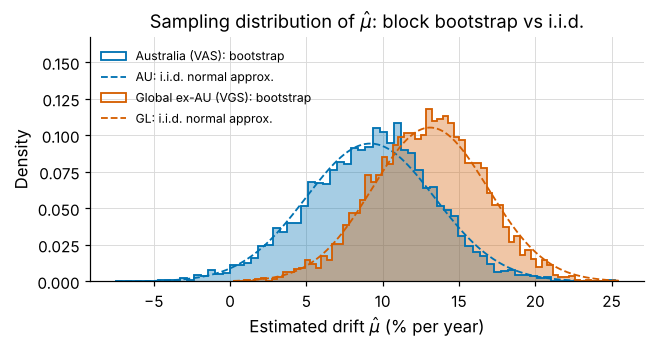

In [7]:
fig, ax = plt.subplots(figsize=(6.0, 3.3))
for k in KEYS:
    v = 100 * boot[f"mu_{k}"]
    ax.hist(v, bins=70, density=True, histtype="stepfilled", alpha=0.35, color=cfg.COLORS[k], lw=0)
    ax.hist(v, bins=70, density=True, histtype="step", color=cfg.COLORS[k], lw=1.2, label=f"{cfg.LABELS[k]}: bootstrap")
    g = np.linspace(v.min(), v.max(), 300)
    ax.plot(g, stats.norm.pdf(g, 100 * est[k]["mu"], 100 * est[k]["se_mu"]), color=cfg.COLORS[k], ls="--", lw=1.2,
            label=f"{k}: i.i.d. normal approx.")
ax.set_xlabel(r"Estimated drift $\hat\mu$ (% per year)")
ax.set_ylabel("Density")
ax.set_title(r"Sampling distribution of $\hat\mu$: block bootstrap vs i.i.d.")
ax.legend(loc="upper left", fontsize=8)
ax.set_ylim(0, ax.get_ylim()[1] * 1.35)
fig.tight_layout()
gu.savefig(fig, "fig08_bootstrap_mu")
plt.show()

## 4. Do the Australian and global drifts differ?

The daily difference $D_k = X^G_k - X^A_k$ has mean $(\nu_G - \nu_A)\Delta t$. Its sample mean is tested
against zero with i.i.d. and Newey–West standard errors (two-sided p-values from the normal distribution),
and a block-bootstrap interval is reported.

In [8]:
D = daily["GL"] - daily["AU"]
d_hat = D.mean() / DT
se_iid = D.std(ddof=1) / np.sqrt(n) / DT
se_hac_d = gu.hac_se_mean(D, lags) / DT
drift_test = pd.DataFrame({
    "estimate": [d_hat, d_hat],
    "SE": [se_iid, se_hac_d],
    "z": [d_hat / se_iid, d_hat / se_hac_d],
    "p-value (two-sided)": [2 * stats.norm.sf(abs(d_hat / se_iid)), 2 * stats.norm.sf(abs(d_hat / se_hac_d))],
    "95% lo": [d_hat - zq * se_iid, d_hat - zq * se_hac_d],
    "95% hi": [d_hat + zq * se_iid, d_hat + zq * se_hac_d],
}, index=pd.Index(["i.i.d.", f"HAC ({lags} lags)"], name="nu_GL - nu_AU"))
drift_test.loc["block bootstrap"] = [d_hat, boot["nu_GL - nu_AU"].std(), np.nan, np.nan,
                                     boot["nu_GL - nu_AU"].quantile(0.025), boot["nu_GL - nu_AU"].quantile(0.975)]
drift_test.to_csv(gu.TAB_DIR / "drift_difference.csv")
drift_test.style.format("{:.4f}", na_rep="--")

,estimate,SE,z,p-value (two-sided),95% lo,95% hi
nu_GL - nu_AU,,,,,,
i.i.d.,0.0413,0.0367,1.1256,0.2603,-0.0306,0.1132
HAC (8 lags),0.0413,0.0301,1.3726,0.1699,-0.0177,0.1003
block bootstrap,0.0413,0.0287,--,--,-0.0156,0.0952


## 5. Frequency check

$\nu$ and $\sigma$ re-estimated from weekly and monthly log returns (built as in notebook 02, each annualised
with its observed number of periods per year). Under GBM all three frequencies estimate the same parameters.
The table also shows the two standard errors: $\operatorname{SE}(\hat\nu)$ stays roughly the same across
frequencies because $T$ is fixed, while $\operatorname{SE}(\hat\sigma)$ grows as $n$ falls.

In [9]:
freq_rows = []
for f, rule in cfg.FREQ_RULES.items():
    R = daily if rule is None else gu.aggregate_returns(daily, rule)
    dt_f = T_years / len(R) if rule else DT          # years per period, from observed periods per year
    for k in KEYS:
        e = gu.gbm_estimates(R[k], dt_f)
        freq_rows.append({"frequency": f, "ETF": k, "n": e["n"], "periods per year": 1 / dt_f,
                          "nu": e["nu"], "SE(nu)": e["se_nu"], "sigma": e["sigma"], "SE(sigma)": e["se_sigma"],
                          "sigma lo": e["sigma_lo"], "sigma hi": e["sigma_hi"]})
freq_tab = pd.DataFrame(freq_rows).set_index(["ETF", "frequency"]).sort_index(level=0, sort_remaining=False)
freq_tab.to_csv(gu.TAB_DIR / "estimates_by_frequency.csv")

ftex = freq_tab[["n", "nu", "SE(nu)", "sigma", "SE(sigma)"]].copy()
ftex[["nu", "SE(nu)", "sigma", "SE(sigma)"]] *= 100
ftex.columns = ["$n$", r"$\hat\nu$", r"SE$(\hat\nu)$", r"$\hat\sigma$", r"SE$(\hat\sigma)$"]
ftex.to_latex(gu.TAB_DIR / "estimates_by_frequency.tex", escape=False, float_format="%.2f",
              caption=("Estimates of $\\nu$ and $\\sigma$ (\\% per year) from daily, weekly and monthly log returns "
                       "over the same period, with SE$(\\hat\\nu)=\\hat\\sigma/\\sqrt{T}$ and "
                       "SE$(\\hat\\sigma)=\\hat\\sigma/\\sqrt{2n}$."),
              label="tab:frequency")
freq_tab.style.format({c: "{:.4f}" for c in freq_tab.columns if c != "n"})

**Annualisation check.** Daily $\hat\sigma\sqrt{252}$ against monthly $\hat\sigma\sqrt{12}$ (using the observed
number of months per year). The difference is expressed in units of the monthly standard error
$\hat\sigma/\sqrt{2n}$, which is much larger than the daily one and so dominates the sampling error of the difference.

In [10]:
for k in KEYS:
    sd_, sm_ = freq_tab.loc[(k, "daily"), "sigma"], freq_tab.loc[(k, "monthly"), "sigma"]
    se_m = freq_tab.loc[(k, "monthly"), "SE(sigma)"]
    print(f"{k}: daily {sd_:.2%}, monthly {sm_:.2%}, difference {sd_ - sm_:+.2%} = "
          f"{(sd_ - sm_) / se_m:+.2f} monthly standard errors")

AU: daily 14.65%, monthly 13.61%, difference +1.05% = +1.30 monthly standard errors
GL: daily 13.13%, monthly 11.86%, difference +1.27% = +1.81 monthly standard errors


## 6. Stability over time

Estimates by calendar year (years with fewer than 126 trading days are left out) and over rolling 2-year
(504-day) windows, each with i.i.d. 95% intervals.

**Fig 7**: annual estimates of $\mu$ (left) and $\sigma$ (right) for both ETFs, each a point with a 95% CI
whisker; dashed lines are the full-sample estimates. The two ETFs are offset slightly on the x-axis.

Years left out (trading days): {2014: 29}
2026 has 218 trading days (partial year)


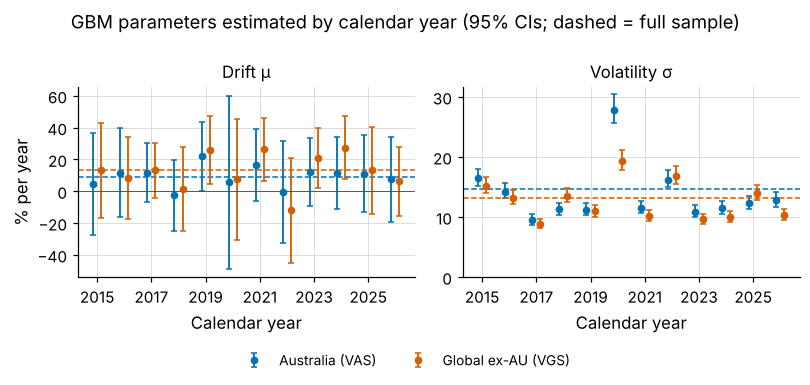

       mu       sigma      
      min   max   min   max
ETF                        
AU   -2.5  21.9   9.5  27.9
GL  -11.8  27.3   8.9  19.4


In [11]:
yr_rows, dropped = [], {}
for y, g in daily.groupby(daily.index.year):
    if len(g) < cfg.MIN_DAYS_PER_YEAR:
        dropped[y] = len(g)
        continue
    for k in KEYS:
        e = gu.gbm_estimates(g[k], DT)
        yr_rows.append({"year": y, "ETF": k, **{c: e[c] for c in
                        ["n", "nu", "nu_lo", "nu_hi", "mu", "mu_lo", "mu_hi", "sigma", "sigma_lo", "sigma_hi"]}})
yearly = pd.DataFrame(yr_rows)
yearly.to_csv(gu.TAB_DIR / "estimates_by_year.csv", index=False)
print(f"Years left out (trading days): {dropped}")
last_year = yearly.year.max()
print(f"{last_year} has {int(yearly[yearly.year == last_year].n.iloc[0])} trading days (partial year)")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4), sharex=True)
for j, k in enumerate(KEYS):
    d = yearly[yearly.ETF == k]
    xpos = d.year + (-0.15 if j == 0 else 0.15)
    for ax, p in zip(axes, ["mu", "sigma"]):
        ax.errorbar(xpos, 100 * d[p], yerr=[100 * (d[p] - d[f"{p}_lo"]), 100 * (d[f"{p}_hi"] - d[p])],
                    fmt="o", ms=4, color=cfg.COLORS[k], elinewidth=1.2, capsize=2, label=cfg.LABELS[k])
        ax.axhline(100 * est[k][p], color=cfg.COLORS[k], ls="--", lw=1)
axes[0].axhline(0, color="0.3", lw=0.6)
axes[0].set_title("Drift μ", fontsize=11)
axes[1].set_title("Volatility σ", fontsize=11)
axes[0].set_ylabel("% per year")
for ax in axes:
    ax.set_xlabel("Calendar year")
    ax.set_xticks(sorted(yearly.year.unique())[::2])
axes[1].set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("GBM parameters estimated by calendar year (95% CIs; dashed = full sample)", fontsize=12)
fig.tight_layout(rect=(0, 0.07, 1, 1))
gu.savefig(fig, "fig07_yearly_estimates")
plt.show()

spread = yearly.groupby("ETF")[["mu", "sigma"]].agg(["min", "max"])
print((100 * spread).round(1).to_string())

**Fig 7b**: rolling 2-year (504-day) estimates of $\mu$ and $\sigma$ with pointwise i.i.d. 95% bands, dated at
the end of each window. Dashed lines are the full-sample estimates.

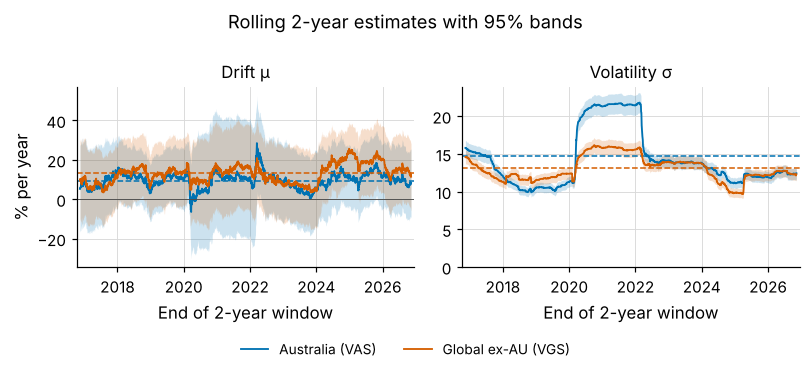

In [12]:
W = cfg.ROLL_EST_WINDOW
roll = {}
for k in KEYS:
    m = daily[k].rolling(W).mean()
    s = daily[k].rolling(W).std()
    sig = s / np.sqrt(DT)
    nu = m / DT
    mu = nu + sig**2 / 2
    se_mu = np.sqrt((sig / np.sqrt(W * DT)) ** 2 + sig**4 / (2 * (W - 1)))
    se_sig = sig / np.sqrt(2 * W)
    roll[k] = pd.DataFrame({"mu": mu, "mu_lo": mu - zq * se_mu, "mu_hi": mu + zq * se_mu,
                            "sigma": sig, "sigma_lo": sig - zq * se_sig, "sigma_hi": sig + zq * se_sig}).dropna()
pd.concat(roll, axis=1).to_csv(gu.TAB_DIR / "estimates_rolling.csv")

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.3), sharex=True)
for k in KEYS:
    r_ = roll[k]
    for ax, p in zip(axes, ["mu", "sigma"]):
        ax.fill_between(r_.index, 100 * r_[f"{p}_lo"], 100 * r_[f"{p}_hi"], color=cfg.COLORS[k], alpha=0.2, lw=0)
        ax.plot(r_.index, 100 * r_[p], color=cfg.COLORS[k], lw=1.2, label=cfg.LABELS[k])
        ax.axhline(100 * est[k][p], color=cfg.COLORS[k], ls="--", lw=1)
axes[0].axhline(0, color="0.3", lw=0.6)
axes[0].set_title("Drift μ", fontsize=11)
axes[1].set_title("Volatility σ", fontsize=11)
axes[0].set_ylabel("% per year")
for ax in axes:
    ax.set_xlabel("End of 2-year window")
    ax.margins(x=0.01)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Rolling 2-year estimates with 95% bands", fontsize=12)
fig.tight_layout(rect=(0, 0.07, 1, 1))
gu.savefig(fig, "fig07b_rolling_estimates")
plt.show()

## 7. Summary printed from the results

Width of the 95% intervals (percentage points per year) for each method, and how much wider the robust
intervals are than the i.i.d. ones.

In [13]:
w = pd.DataFrame({
    "i.i.d. width": table3["iid hi"] - table3["iid lo"],
    "HAC width": table3["HAC hi"] - table3["HAC lo"],
    "bootstrap width": table3["boot hi"] - table3["boot lo"],
})
w["bootstrap / i.i.d."] = w["bootstrap width"] / w["i.i.d. width"]
scale = pd.Series(100.0, index=w.index)
scale["rho"] = 1.0
w[["i.i.d. width", "HAC width", "bootstrap width"]] = w[["i.i.d. width", "HAC width", "bootstrap width"]].mul(scale, axis=0)
print("Widths in % per year (rho: unitless)")
w.round(3)

Widths in % per year (rho: unitless)


,i.i.d. width,HAC width,bootstrap width,bootstrap / i.i.d.
parameter,,,,
nu_AU,16.576,15.940,16.569,1.000
mu_AU,16.570,15.940,16.195,0.977
sigma_AU,0.739,NaN,4.348,5.887
nu_GL,14.852,13.725,14.222,0.958
mu_GL,14.846,13.725,14.040,0.946
sigma_GL,0.662,NaN,2.390,3.612
rho,0.047,NaN,0.125,2.664
